# STAGE 2 — TASK 4: HỌC CÓ GIÁM SÁT & PHÂN LOẠI NHÃN CỤM

**Dự án:** CGV Movie Analytics  
**Đầu vào:** `cgv_pca_transformed.csv` và `cgv_clustered_suatchieu.csv` từ Task 1/Task 2.

## Mục tiêu
Dùng 25 thành phần PCA làm đặc trưng `X` và `Cluster_Label` do K-Means tạo ở Task 2 làm nhãn `y`. Huấn luyện, so sánh `LogisticRegression` và `DecisionTreeClassifier` trên cùng một tập train/test; đánh giá bằng Precision, Recall, Accuracy, F1-score, classification report và confusion matrix.



## 1. Import thư viện

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42


## 2. Đọc dữ liệu và tạo X, y

In [2]:
DATA_DIR = Path.cwd()
if not (DATA_DIR / "cgv_pca_transformed.csv").exists():
    DATA_DIR = DATA_DIR / "Stage2"

PCA_PATH = DATA_DIR / "cgv_pca_transformed.csv"
CLUSTER_PATH = DATA_DIR / "cgv_clustered_suatchieu.csv"

if not PCA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy file đặc trưng PCA: {PCA_PATH}")
if not CLUSTER_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy file nhãn cụm: {CLUSTER_PATH}")

X = pd.read_csv(PCA_PATH)
clustered_df = pd.read_csv(CLUSTER_PATH)

if "Cluster_Label" not in clustered_df.columns:
    raise ValueError("File cgv_clustered_suatchieu.csv không có cột Cluster_Label.")
if len(X) != len(clustered_df):
    raise ValueError(
        f"Số dòng không khớp: PCA có {len(X)} dòng, nhãn cụm có {len(clustered_df)} dòng. "
        "Hãy chạy lại Task 1 và Task 2 để đồng bộ dữ liệu."
    )

y = clustered_df["Cluster_Label"]
if X.isna().any().any() or y.isna().any():
    raise ValueError("X hoặc y có giá trị thiếu; hãy xử lý dữ liệu trước khi huấn luyện.")

print(f"Số mẫu: {len(X)} | Số đặc trưng: {X.shape[1]} | Số lớp: {y.nunique()}")
display(X.head())
display(y.value_counts().sort_index().rename("Số mẫu").to_frame())


Số mẫu: 1172 | Số đặc trưng: 25 | Số lớp: 9


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25
0,-2.707712,4.790861,0.161704,-0.659364,0.296295,-0.075878,1.005484,-0.884608,1.540959,-2.236279,...,-0.293159,-0.752915,-1.864031,0.848051,3.008151,-0.700764,2.688407,0.855961,-0.907663,-0.234921
1,-3.168422,-2.276626,-1.178454,2.569261,1.181923,2.735661,-0.248027,-0.671508,-0.442721,-2.112849,...,0.707275,1.020462,-0.115892,0.152185,0.085041,-0.925857,0.176390,-1.976880,1.298072,-0.388286
2,-3.438450,-2.713909,-0.215170,0.519931,0.136968,3.273914,-0.773759,-1.404559,-0.264249,-0.757613,...,-0.152153,0.905922,-0.141756,0.048379,-0.049671,0.087379,0.184062,0.336404,-0.239748,-0.021830
3,2.155350,-0.086598,0.027964,-0.302171,0.026462,0.297379,-0.201556,0.096294,-0.056755,-0.987265,...,-0.678000,0.238726,-0.151372,0.009917,-0.007947,-0.034332,0.040068,0.048968,-0.053554,-0.028673
4,2.163451,-0.085711,0.058681,-0.327334,0.021568,0.186618,-0.224276,0.108459,0.000747,-1.037358,...,-0.338018,0.453027,-0.078272,0.001693,-0.028902,-0.047000,0.085377,0.068267,-0.052213,-0.048290


,Số mẫu
Cluster_Label,
0,110
1,488
2,136
3,130
4,134
5,49
6,20
7,54
8,51


## 3. Kiểm tra mất cân bằng và chia train/test

In [3]:
class_counts = y.value_counts().sort_index()
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Tỷ lệ lớp lớn nhất/nhỏ nhất: {imbalance_ratio:.1f}:1")
print("Áp dụng class_weight='balanced' cho cả hai mô hình.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Train: {len(X_train)} mẫu | Test: {len(X_test)} mẫu")
display(pd.DataFrame({
    "Toàn bộ": y.value_counts(normalize=True).sort_index(),
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index(),
}).round(3))


Tỷ lệ lớp lớn nhất/nhỏ nhất: 24.4:1
Áp dụng class_weight='balanced' cho cả hai mô hình.
Train: 937 mẫu | Test: 235 mẫu


,Toàn bộ,Train,Test
Cluster_Label,,,
0,0.094,0.094,0.094
1,0.416,0.416,0.417
2,0.116,0.116,0.115
3,0.111,0.111,0.111
4,0.114,0.114,0.115
5,0.042,0.042,0.043
6,0.017,0.017,0.017
7,0.046,0.046,0.047
8,0.044,0.044,0.043


## 4. Huấn luyện hai mô hình

In [4]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"Đã huấn luyện: {name}")


Đã huấn luyện: Logistic Regression
Đã huấn luyện: Decision Tree


## 5. So sánh chỉ số đánh giá

In [5]:
comparison_rows = []
for name, y_pred in predictions.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (Weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison_df.round(3))


,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),F1-score (Weighted)
Model,,,,,
Logistic Regression,1.0,1.0,1.0,1.0,1.0
Decision Tree,1.0,1.0,1.0,1.0,1.0


## 6. Classification report và Confusion Matrix


===== Logistic Regression — Classification Report =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        22
           1       1.00      1.00      1.00        98
           2       1.00      1.00      1.00        27
           3       1.00      1.00      1.00        26
           4       1.00      1.00      1.00        27
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4
           7       1.00      1.00      1.00        11
           8       1.00      1.00      1.00        10

    accuracy                           1.00       235
   macro avg       1.00      1.00      1.00       235
weighted avg       1.00      1.00      1.00       235


===== Decision Tree — Classification Report =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        22
           1       1.00      1.00      1.00        98
           2       1.00 

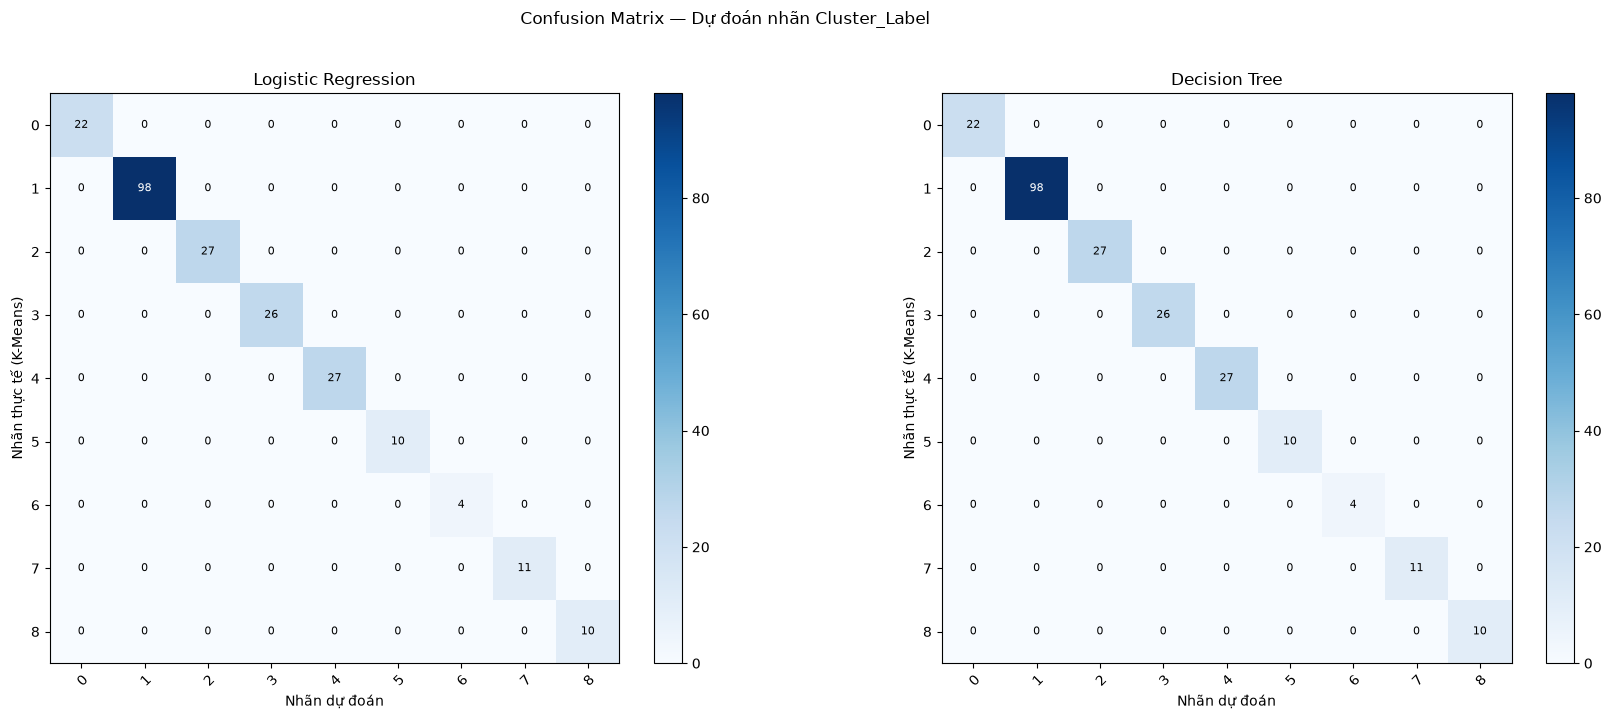

In [6]:
class_labels = sorted(y.unique())
fig, axes = plt.subplots(1, len(models), figsize=(18, 7))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    print(f"\n===== {name} — Classification Report =====")
    print(classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=[str(label) for label in class_labels],
        zero_division=0,
    ))

    matrix = confusion_matrix(y_test, y_pred, labels=class_labels)
    image = ax.imshow(matrix, interpolation="nearest", cmap="Blues")
    ax.figure.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ax.set(
        title=name,
        xlabel="Nhãn dự đoán",
        ylabel="Nhãn thực tế (K-Means)",
        xticks=np.arange(len(class_labels)),
        yticks=np.arange(len(class_labels)),
        xticklabels=class_labels,
        yticklabels=class_labels,
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    threshold = matrix.max() / 2 if matrix.size else 0
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            ax.text(
                column,
                row,
                format(matrix[row, column], "d"),
                ha="center",
                va="center",
                color="white" if matrix[row, column] > threshold else "black",
                fontsize=8,
            )

fig.suptitle("Confusion Matrix — Dự đoán nhãn Cluster_Label", y=1.02)
fig.tight_layout()
plt.show()


## 7. Kết luận

Dựa vào bảng chỉ số, so sánh Macro F1 để đánh giá công bằng hơn giữa 9 cụm có kích thước khác nhau; dùng confusion matrix và classification report để nêu rõ cụm nào dự đoán tốt hoặc thường bị nhầm. Kết quả chỉ phản ánh mức độ mô hình học lại nhãn do K-Means tạo ra trên dữ liệu này.